# Originación: CUSUM, falsas alarmas y demora

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Umbral calibrado:** 5.604
- **Falsa alarma en 120 días:** 0.0633
- **Réplicas independientes de evaluación:** 600
- **Escenarios de cambio:** 5
- **FA con phi=0,85:** 0.795
- **FA al reutilizar umbral en 5 canales:** 0.28
- **FA con umbral conjunto:** 0.04

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Qué umbral detecta un cambio sin alertar constantemente? Calibramos el máximo de CUSUM en horizontes de 120 días y evaluamos falsas alarmas en réplicas independientes.

### Supuestos y población

Residuos diarios normales e independientes bajo estabilidad. Se simula un cambio después del día 60. El límite se calibra para una sola serie y un solo horizonte; no controla automáticamente muchos canales ni monitoreo indefinido.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Acumular evidencia de un cambio


$$S_t=\max(0,S_{t-1}+z_t-k),\quad \mathrm{alarma}\iff S_t>h.$$

$k$ penaliza pequeñas oscilaciones y $h$ fija tolerancia de evidencia. Un umbral no puede copiarse sin considerar escala, dependencia, número de series y horizonte.

In [2]:
def cusum(z,k=.5):
    result=np.zeros_like(z,dtype=float);state=0.
    for t,value in enumerate(z):
        state=max(0.,state+value-k);result[t]=state
    return result
horizon=120;change_day=60
calibration_paths=rng.normal(size=(600,horizon))
maxima=np.array([cusum(path).max() for path in calibration_paths])
h=float(np.quantile(maxima,.95,method='higher'))
validation_paths=rng.normal(size=(600,horizon))
false_alarm=np.array([cusum(path).max()>h for path in validation_paths])
false_alarm_rate=float(false_alarm.mean())
def wilson(success,n,z=1.96):
    p=success/n;den=1+z*z/n
    center=(p+z*z/(2*n))/den
    radius=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-radius,center+radius
ci=wilson(int(false_alarm.sum()),len(false_alarm))
display(pd.DataFrame({'umbral_h':[h],'FA_horizonte_test':[false_alarm_rate],'limite95_inferior':[ci[0]],'limite95_superior':[ci[1]],'replicas':[len(false_alarm)]}))

,umbral_h,FA_horizonte_test,limite95_inferior,limite95_superior,replicas
0,5.6041,0.0633,0.0465,0.0857,600


El intervalo Wilson corresponde a la tasa de réplicas con al menos una alarma en 120 días. No es la tasa diaria ni un intervalo del umbral. Las simulaciones de calibración y validación son diferentes.

## 2. Cambio y causa no son lo mismo


Una subida en omisiones observadas puede provenir de un cambio de proceso o de un cambio en registro. Si producen la misma serie $z_t$, CUSUM devuelve exactamente la misma evidencia: no identifica causalidad ni intención.

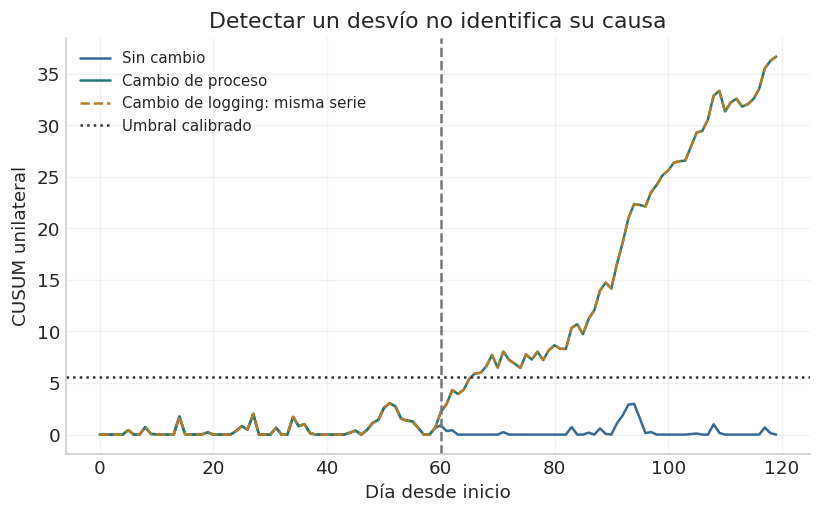

In [3]:
noise=rng.normal(size=horizon)
stable=noise.copy();deviation=noise.copy();deviation[change_day:]+=1.3
logging=deviation.copy()
fig,ax=plt.subplots()
ax.plot(cusum(stable),label='Sin cambio',color=BLUE)
ax.plot(cusum(deviation),label='Cambio de proceso',color=TEAL)
ax.plot(cusum(logging),label='Cambio de logging: misma serie',color=GOLD,linestyle='--')
ax.axhline(h,color='#333333',linestyle=':',label='Umbral calibrado')
ax.axvline(change_day,color='#777777',linestyle='--');ax.set(xlabel='Día desde inicio',ylabel='CUSUM unilateral',title='Detectar un desvío no identifica su causa');ax.legend(fontsize=9);plt.show()

Las dos curvas de cambio coinciden deliberadamente. La explicación necesita bitácora de versión, conciliación de eventos y verificación independiente. El detector estadístico por sí solo no demuestra fraude.

## 3. Tamaño de cambio y tiempo de detección


La primera alarma puede llegar antes del cambio. Se reporta por separado la tasa pre-cambio y la detección dentro del horizonte entre trayectorias sin alarma previa. La mediana de demora usa solo trayectorias detectadas; omite censuradas y se etiqueta así.

,shift,replicas,prealarma,elegibles_sin_prealarma,deteccion_en_elegibles,detectados,mediana_dias_solo_detectados
0,0.3000,400,0.0450,382,0.3455,132,30.0000
1,0.6000,400,0.0275,389,0.8663,337,21.0000
2,1.0000,400,0.0300,388,1.0000,388,10.0000
3,1.5000,400,0.0225,391,1.0000,391,5.0000
4,2.0000,400,0.0300,388,1.0000,388,4.0000


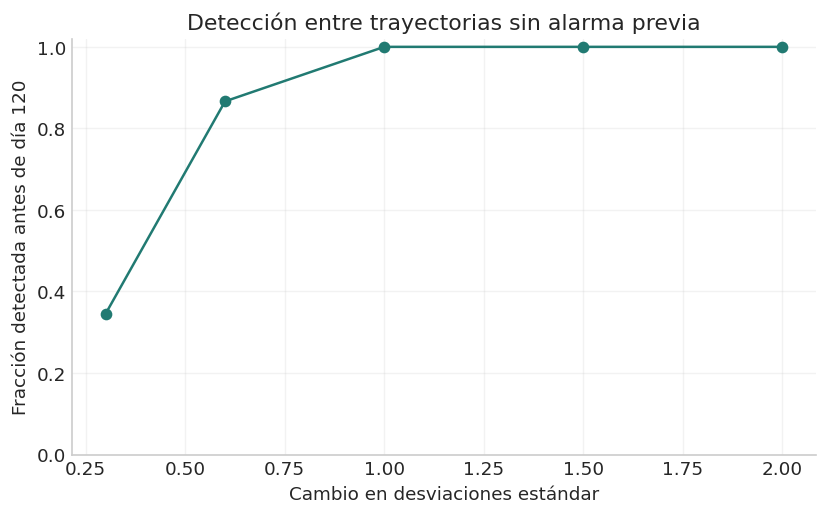

In [4]:
records=[]
for shift in [.3,.6,1.,1.5,2.]:
    paths=rng.normal(size=(400,horizon));paths[:,change_day:]+=shift
    pre_count=0;eligible=0;delays=[]
    for path in paths:
        series=cusum(path);alarms=np.flatnonzero(series>h)
        if len(alarms) and alarms[0]<change_day:pre_count+=1;continue
        eligible+=1
        later=alarms[alarms>=change_day]
        if len(later):delays.append(int(later[0]-change_day+1))
    records.append({'shift':shift,'replicas':400,'prealarma':pre_count/400,'elegibles_sin_prealarma':eligible,
                    'deteccion_en_elegibles':len(delays)/eligible,'detectados':len(delays),
                    'mediana_dias_solo_detectados':float(np.median(delays)) if delays else np.nan})
detection=pd.DataFrame(records);display(detection)
fig,ax=plt.subplots();ax.plot(detection['shift'],detection['deteccion_en_elegibles'],color=TEAL,marker='o')
ax.set(xlabel='Cambio en desviaciones estándar',ylabel='Fracción detectada antes de día 120',ylim=(0,1.02),title='Detección entre trayectorias sin alarma previa');plt.show()

La comparación mantiene h y k congelados y varía solo la simulación de cambio. La tasa pre-cambio y los casos censurados se conservan en la tabla; no se presenta la mediana de detectados como demora poblacional.

## Desarrollo ampliado: modelo, estimación y uso


**Uso:** detectar aumentos persistentes de una señal de control y organizar revisión. **Entrada:** residuos estandarizados con referencia congelada, horizonte y canales. **Salida:** fecha de alerta y evidencia acumulada. El modelo no atribuye causa ni intención.

El umbral de una sola serie normal independiente no se puede copiar a cincuenta canales correlacionados. Se amplían derivaciones con razón de verosimilitud, autocorrelación, multiplicidad y censura de demoras. Estos ejercicios cambian supuestos de forma controlada sin volver a elegir h con el test.

In [5]:
advanced_metrics = {}
advanced_rng = np.random.default_rng(9221)

### 4. CUSUM como acumulación de log-verosimilitud


Para $z\sim N(0,1)$ contra $N(\delta,1)$:
$$\log\frac{f_\delta(z)}{f_0(z)}=\delta z-\frac{\delta^2}{2}=\delta(z-\delta/2).$$

Para delta positivo y constante, la recursión normalizada usa k=delta/2. El h calibrado controla otra dimensión: tolerancia a falsas alarmas bajo la referencia. Una referencia estimada o autocorrelación modifica esa calibración.

In [6]:
from scipy.stats import norm
z_grid=np.linspace(-3,4,50);delta=1.
llr_direct=norm.logpdf(z_grid,loc=delta)-norm.logpdf(z_grid,loc=0)
llr_formula=delta*z_grid-delta**2/2
assert np.allclose(llr_direct,llr_formula)
llr_table=pd.DataFrame({'z':z_grid[::8],'log_ratio':llr_direct[::8],'incremento_normalizado':z_grid[::8]-.5})
display(llr_table)

,z,log_ratio,incremento_normalizado
0,-3.0000,-3.5000,-3.5000
1,-1.8571,-2.3571,-2.3571
2,-0.7143,-1.2143,-1.2143
3,0.4286,-0.0714,-0.0714
4,1.5714,1.0714,1.0714
5,2.7143,2.2143,2.2143
6,3.8571,3.3571,3.3571


**Interpretación y uso.** Esta derivación explica k=0,5 para un cambio de una desviación estándar en el caso idealizado. No justifica usarlo igual sobre tasas crudas, volúmenes variables o residuos con otra distribución.

### 5. Autocorrelación rompe la referencia independiente


Se genera $z_t=\phi z_{t-1}+\sqrt{1-\phi^2}\epsilon_t$ con inicio estacionario. Su varianza marginal es 1, pero observaciones positivas se agrupan si phi>0. Se conserva h de la referencia independiente para medir sensibilidad.

,phi,FA_en_120_dias,replicas
0,0.0000,0.0925,400
1,0.3000,0.3250,400
2,0.6000,0.6950,400
3,0.8500,0.7950,400


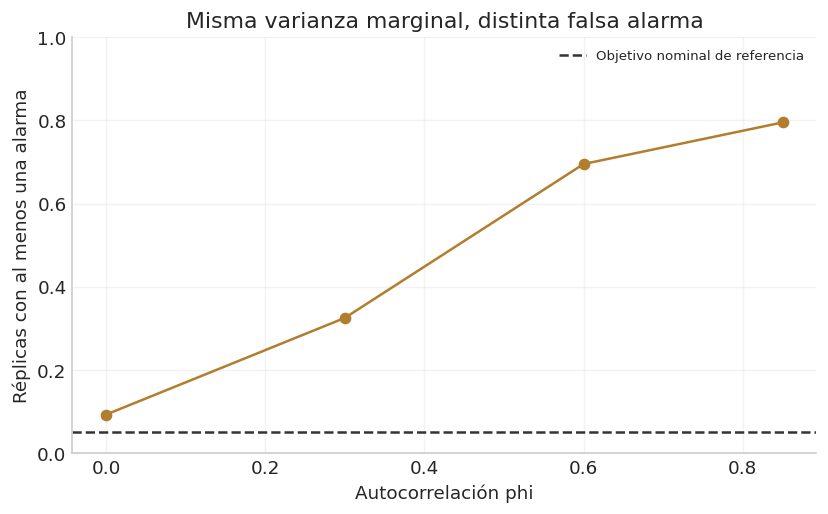

In [7]:
correlation_rows=[]
for phi in [0.,.3,.6,.85]:
    simulations=advanced_rng.normal(size=(400,horizon))
    paths=np.empty_like(simulations);paths[:,0]=simulations[:,0]
    for t in range(1,horizon):paths[:,t]=phi*paths[:,t-1]+np.sqrt(1-phi*phi)*simulations[:,t]
    rate=np.mean([cusum(path).max()>h for path in paths])
    correlation_rows.append({'phi':phi,'FA_en_120_dias':rate,'replicas':len(paths)})
correlation_rows=pd.DataFrame(correlation_rows);display(correlation_rows)
fig,ax=plt.subplots();ax.plot(correlation_rows['phi'],correlation_rows['FA_en_120_dias'],color=GOLD,marker='o')
ax.axhline(.05,color='#333333',linestyle='--',label='Objetivo nominal de referencia')
ax.set(ylim=(0,1),xlabel='Autocorrelación phi',ylabel='Réplicas con al menos una alarma',title='Misma varianza marginal, distinta falsa alarma');ax.legend(fontsize=8);plt.show()

**Interpretación y uso.** No se recalibra con estas réplicas: la curva muestra un fallo del supuesto original. Para una aplicación se necesita modelar residuos, recalibrar con bloques o simular la dependencia relevante y reservar otro conjunto para evaluar.

### 6. Múltiples canales: del umbral individual al conjunto


Para canales independientes con probabilidad individual alpha, la probabilidad de alguna alarma es $1-(1-\alpha)^G$. Esa fórmula no vale automáticamente con correlación. Se calibra además un umbral por máximo conjunto de cinco canales a horizonte fijo.

,politica,umbral,FA_alguno_en_5_canales,replicas
0,Reutilizar h individual,5.6041,0.2800,300
1,Calibrar máximo conjunto,7.6535,0.0400,300


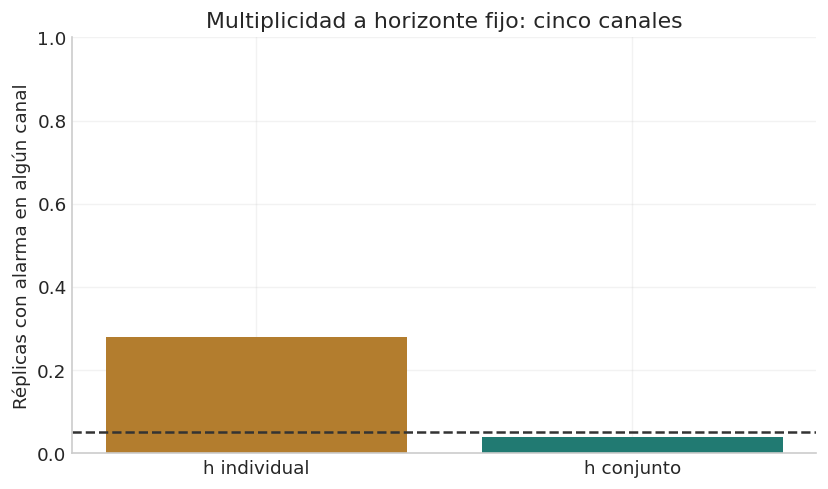

In [8]:
G=5
multi_cal=advanced_rng.normal(size=(300,G,horizon))
max_joint=np.array([max(cusum(channel).max() for channel in replication) for replication in multi_cal])
h_joint=float(np.quantile(max_joint,.95,method='higher'))
multi_test=advanced_rng.normal(size=(300,G,horizon))
max_joint_test=np.array([max(cusum(channel).max() for channel in replication) for replication in multi_test])
individual_reuse_rate=float(np.mean(max_joint_test>h))
joint_rate=float(np.mean(max_joint_test>h_joint))
display(pd.DataFrame({'politica':['Reutilizar h individual','Calibrar máximo conjunto'],'umbral':[h,h_joint],'FA_alguno_en_5_canales':[individual_reuse_rate,joint_rate],'replicas':[300,300]}))
fig,ax=plt.subplots();ax.bar(['h individual','h conjunto'],[individual_reuse_rate,joint_rate],color=[GOLD,TEAL])
ax.axhline(.05,color='#333333',linestyle='--');ax.set(ylim=(0,1),ylabel='Réplicas con alarma en algún canal',title='Multiplicidad a horizonte fijo: cinco canales');plt.show()

**Interpretación y uso.** La calibración usa otras réplicas y respeta el presupuesto nominal solo en el sentido estadístico del simulador. No controla una operación indefinida, reinicios ni nuevas versiones de canal. Publicar incertidumbre de Monte Carlo antes de exigir una igualdad exacta.

### 7. Demoras censuradas y costo de detección


La demora de un cambio es $D=T_{alarma}-T_{cambio}+1$. Si no se detecta antes de H, D está censurada; la mediana de detectados no estima la mediana de todos. Se añade un costo ilustrativo por día de exposición y un costo por prealarma, con parámetros declarados.

In [9]:
per_day_loss=25_000.;false_case_cost=30_000.
delay_cost_rows=[]
for row in records:
    eligible=row['elegibles_sin_prealarma'];detected=row['detectados']
    # This is a proxy based on a detected-only median, NOT expected full delay.
    median_proxy=row['mediana_dias_solo_detectados']
    censoring=1-detected/eligible
    delay_cost_rows.append({'cambio':row['shift'],'censura_en_elegibles':censoring,
                            'mediana_detectados_dias':median_proxy,
                            'costo_mediana_detectados_COP':median_proxy*per_day_loss,
                            'costo_prealarma_promedio_COP':row['prealarma']*false_case_cost})
display(pd.DataFrame(delay_cost_rows))
assert h_joint>=h
advanced_metrics.update({'FA con phi=0,85':round(float(correlation_rows.iloc[-1]['FA_en_120_dias']),4),'FA al reutilizar umbral en 5 canales':round(individual_reuse_rate,4),'FA con umbral conjunto':round(joint_rate,4)})

,cambio,censura_en_elegibles,mediana_detectados_dias,costo_mediana_detectados_COP,costo_prealarma_promedio_COP
0,0.3000,0.6545,30.0000,"750,000.0000","1,350.0000"
1,0.6000,0.1337,21.0000,"525,000.0000",825.0000
2,1.0000,0.0000,10.0000,"250,000.0000",900.0000
3,1.5000,0.0000,5.0000,"125,000.0000",675.0000
4,2.0000,0.0000,4.0000,"100,000.0000",900.0000


**Interpretación y uso.** El costo basado en mediana se etiqueta como proxy y no se suma para declarar beneficio esperado. Un modelo completo de pérdida necesita tiempos de exposición, casos censurados, contención real y capacidad de investigación; esos datos no están simulados aquí.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [10]:
assert np.array_equal(cusum(deviation),cusum(logging))
assert 0<=false_alarm_rate<=1
assert ((detection['detectados']<=detection['elegibles_sin_prealarma'])&(detection['elegibles_sin_prealarma']>0)).all()
assert ci[0]<=false_alarm_rate<=ci[1]

## Resultados computados

In [11]:
metrics = {'Umbral calibrado': round(h,3), 'Falsa alarma en 120 días': round(false_alarm_rate,4), 'Réplicas independientes de evaluación': len(false_alarm), 'Escenarios de cambio': len(detection)}
metrics.update(advanced_metrics)
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Umbral calibrado": 5.604, "Falsa alarma en 120 días": 0.0633, "Réplicas independientes de evaluación": 600, "Escenarios de cambio": 5, "FA con phi=0,85": 0.795, "FA al reutilizar umbral en 5 canales": 0.28, "FA con umbral conjunto": 0.04}


## Ideas y preguntas para continuar

1. Introducir residuos autocorrelacionados para probar cuándo se pierde la calibración.
2. Calibrar máximos conjuntos de varios canales, en vez de copiar el umbral de una serie.
3. Comparar reinicios y períodos de espera después de investigar una alarma.
4. Modelar señales de logging y calidad en un canal separado.
5. Incorporar el costo de demora y la capacidad de revisión a la selección de umbral.

## Fuentes y relación con el proyecto

- [NIST: CUSUM](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm).
- [NIST: average run length](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc3131.htm).
Este notebook evalúa probabilidad de alarma a horizonte fijo, no estima ARL infinito.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.

## Uso responsable y ficha mínima de salida

Antes de una aplicación institucional, registrar población, corte de información, versión del modelo, horizonte, unidades y cobertura de fuentes. Separar score de anomalía, probabilidad estimada y costo por acción. Una discrepancia o un desvío requiere evidencia independiente antes de llamarlo fraude. El experimento está completo en su alcance sintético; no sustituye calibración externa, integración de datos o validación independiente.

## Preguntas para refutar el desarrollo

1. ¿La mejora persiste al cambiar el mecanismo generador y la cohorte?
2. ¿Qué variable solo estaría disponible después de decidir?
3. ¿Cuánto del beneficio depende de una eficacia o cobertura supuesta?
4. ¿Qué caso legítimo produce la misma señal?
5. ¿Puede otra persona reconstruir el resultado desde las celdas y los parámetros?

## Diccionario de símbolos y unidades

| Símbolo | Significado en este notebook | Unidad o restricción |
|---|---|---|
| z, δ | Residuo y cambio objetivo | Desviaciones estándar |
| k, h | Referencia del incremento y umbral | Escala CUSUM normalizada |
| S | Evidencia acumulada unilateral | No es probabilidad de fraude |
| φ | Autocorrelación AR(1) | Supuesto de dependencia |
| G, H | Número de canales y horizonte | Conteo y días |
| D | Demora desde cambio hasta alarma | Días; posible censura |

## Modelos y casos de uso

| Modelo o técnica | Para qué usarlo | Condición para interpretar su salida |
|---|---|---|
| CUSUM unilateral | Detectar incremento persistente | Referencia y escala deben ser estables |
| Calibración por simulación | Elegir h para un horizonte declarado | Separar calibración y evaluación |
| Máximo conjunto | Controlar alguna alerta en varios canales | Reproducir dependencia y número de canales |
| Análisis de demora | Evaluar detección frente a carga | No ignorar prealarmas ni censurados |

Referencias técnicas adicionales: [logit](https://scikit-learn.org/stable/modules/linear_model.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). Las distribuciones, datos y resultados de este notebook son sintéticos y se generan en las celdas.